# Predictive Modeling for Business Entity Resolution
**Course project: Predictive Analytics.** Manthan Vats (2427030314), Peddi Reddy Srikar Reddy (2427030741)

Business records from three sources describe the same companies with different spellings,
abbreviations, scripts and missing address parts. For every Source 1 record we predict which
Source 2/3 records are the same business. The task is cast as **binary classification of
candidate pairs** (match / non-match), followed by a per-entity decision on how many
candidates to accept, and a **count model** for the number of matches per entity.

This notebook covers the syllabus pipeline end to end:
1. data preparation and EDA (missing values, scripts, outliers, feature distributions)
2. feature engineering and selection
3. logistic regression with coefficient inference, LDA, QDA and a gradient-boosting reference
4. grouped cross-validation, grid search and random search
5. F1, AUC-ROC and the challenge metric (macro F0.5), overfitting/underfitting checks
6. Poisson, negative binomial and multinomial logit models for the match count

Data: `scripts/study/build_study_data.py` draws a 5% sample of the Amazon ML Challenge 2026
training set and runs the blocking stage of our challenge pipeline on it. The lockbox split
(20% of entities, never used while building the challenge system) is the test set here.

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import statsmodels.api as sm
from scipy import stats
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix, f1_score, log_loss,
                             mean_absolute_error, mean_squared_error, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold, RandomizedSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ber.decide import expected_f05_topk
from ber.pipeline import A_FEATS

warnings.filterwarnings("ignore")
STUDY = ROOT / "data" / "study"
FIG = ROOT / "paper" / "figures"
REP = ROOT / "reports"
APP = ROOT / "app" / "models"
for d in (FIG, REP, APP):
    d.mkdir(parents=True, exist_ok=True)
RESULTS = {}
SEED = 2026
rng = np.random.default_rng(SEED)

C = {"LR": "#2a78d6", "LDA": "#eb6834", "QDA": "#1baf7a", "LightGBM": "#6250d6", "match": "#2a78d6", "non": "#eb6834"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#8a8984", "axes.labelcolor": "#2b2a27", "xtick.color": "#52514e",
                     "ytick.color": "#52514e", "legend.frameon": False, "lines.linewidth": 1.6})


def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

## 1. Data overview

In [2]:
pairs = pl.read_parquet(STUDY / "pairs.parquet")
ent = pl.read_parquet(STUDY / "entities.parquet")
recs = pl.read_parquet(STUDY / "records.parquet")
print(f"records {recs.height:,}  S1 entities {ent.height:,}  candidate pairs {pairs.height:,}  positives {pairs['y'].sum():,}")
overview = (recs.group_by("src", "country").len().sort("src", "country")
            .pivot(on="country", index="src", values="len"))
print(overview)
cov = pairs["y"].sum() / ent["n_true"].sum()
RESULTS["data"] = {"records": recs.height, "s1": ent.height, "pairs": pairs.height, "pos_pairs": int(pairs["y"].sum()),
                   "true_pairs": int(ent["n_true"].sum()), "blocking_recall": cov,
                   "pairs_per_s1": pairs.height / ent.height, "pos_rate": float(pairs["y"].mean())}
print(f"blocking recall {cov:.4f}, {pairs.height / ent.height:.1f} candidates per S1, positive rate {pairs['y'].mean():.4f}")

records 625,153  S1 entities 110,341  candidate pairs 5,796,352  positives 378,419
shape: (3, 3)
┌─────┬────────┬────────┐
│ src ┆ India  ┆ US     │
│ --- ┆ ---    ┆ ---    │
│ str ┆ u32    ┆ u32    │
╞═════╪════════╪════════╡
│ 1   ┆ 44262  ┆ 66079  │
│ 2   ┆ 100841 ┆ 150166 │
│ 3   ┆ 106061 ┆ 157744 │
└─────┴────────┴────────┘
blocking recall 0.9940, 52.5 candidates per S1, positive rate 0.0653


## 2. Data preparation: missing values, scripts and outliers

In [3]:
quality = (
    recs.with_columns(
        (pl.col("business_address").fill_null("").str.strip_chars() == "").alias("addr_missing"),
        pl.col("business_name").fill_null("").str.contains(r"[ऀ-ൿ]").alias("indic_script"),
        pl.col("business_name").fill_null("").str.len_chars().alias("name_len"),
    )
    .group_by("src", "country")
    .agg(pl.col("addr_missing").mean().round(4), pl.col("indic_script").mean().round(4),
         pl.col("name_len").median().alias("name_len_median"), pl.col("name_len").quantile(0.99).alias("name_len_p99"))
    .sort("src", "country")
)
print(quality)
quality.write_csv(REP / "data_quality.csv")
RESULTS["quality"] = quality.to_dicts()

ex = recs.filter(pl.col("country") == "India").filter(pl.col("business_name").str.contains(r"[ऀ-ॿ]")).head(3)
print(ex.select("business_name", "name_n", "business_address", "addr_n"))

shape: (6, 6)
┌─────┬─────────┬──────────────┬──────────────┬─────────────────┬──────────────┐
│ src ┆ country ┆ addr_missing ┆ indic_script ┆ name_len_median ┆ name_len_p99 │
│ --- ┆ ---     ┆ ---          ┆ ---          ┆ ---             ┆ ---          │
│ str ┆ str     ┆ f64          ┆ f64          ┆ f64             ┆ f64          │
╞═════╪═════════╪══════════════╪══════════════╪═════════════════╪══════════════╡
│ 1   ┆ India   ┆ 0.0          ┆ 0.0          ┆ 27.0            ┆ 44.0         │
│ 1   ┆ US      ┆ 0.0          ┆ 0.0          ┆ 22.0            ┆ 41.0         │
│ 2   ┆ India   ┆ 0.029        ┆ 0.235        ┆ 27.0            ┆ 49.0         │
│ 2   ┆ US      ┆ 0.036        ┆ 0.0          ┆ 23.0            ┆ 46.0         │
│ 3   ┆ India   ┆ 0.0304       ┆ 0.1315       ┆ 27.0            ┆ 51.0         │
│ 3   ┆ US      ┆ 0.0351       ┆ 0.0          ┆ 23.0            ┆ 50.0         │
└─────┴─────────┴──────────────┴──────────────┴─────────────────┴──────────────┘
shape: (3, 4)


The normalisation step (from the challenge pipeline) lower-cases text, expands common
abbreviations, transliterates Devanagari with a dictionary learned from training matches and
`anyascii`, and strips leading zeros from house numbers. Missing addresses are kept as empty strings
and flagged by a feature (`c_addr_empty`); house-number features use -1 when either side has no number,
with an explicit indicator `num_missing` added below.

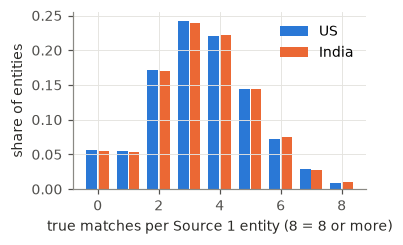

match count mean 3.450, variance 2.885, zero share 0.056


In [4]:
nt = ent.group_by("country", "n_true").len().sort("country", "n_true")
fig, ax = plt.subplots(figsize=(3.5, 2.3))
for i, (c, col) in enumerate((("US", C["LR"]), ("India", C["LDA"]))):
    d = nt.filter(pl.col("country") == c).with_columns(pl.col("n_true").clip(0, 8))
    d = d.group_by("n_true").agg(pl.col("len").sum()).sort("n_true")
    share = d["len"] / d["len"].sum()
    ax.bar(d["n_true"].to_numpy() + (i - 0.5) * 0.38, share, width=0.36, color=col, label=c)
ax.set_xlabel("true matches per Source 1 entity (8 = 8 or more)")
ax.set_ylabel("share of entities")
ax.legend()
save(fig, "fig_match_counts")
m, v = ent["n_true"].mean(), ent["n_true"].var()
RESULTS["count_stats"] = {"mean": m, "var": v, "zero_share": float((ent["n_true"] == 0).mean())}
print(f"match count mean {m:.3f}, variance {v:.3f}, zero share {(ent['n_true'] == 0).mean():.3f}")

## 3. Feature engineering
Each candidate pair carries 43 features in four groups:
* **blocking similarities**: TF-IDF cosine on name character 3-grams (`name_cos`), name words (`nword_cos`),
  address words (`addr_cos`), house numbers (`num_cos`) and their weighted sum (`joint`), plus the rank in each search;
* **context**: gap to the best candidate of the same S1 and of the same candidate (`*_gap_s1`, `*_gap_cand`),
  ranks, number of candidates per S1 and per candidate;
* **string similarity** (rapidfuzz): ratio, token sort/set, partial ratio, Jaro-Winkler on names; token set/sort
  and partial ratio on addresses; Jaccard and first-number agreement on house numbers;
* **record properties**: name/address lengths, empty address, Devanagari script, source of the candidate.

43 features


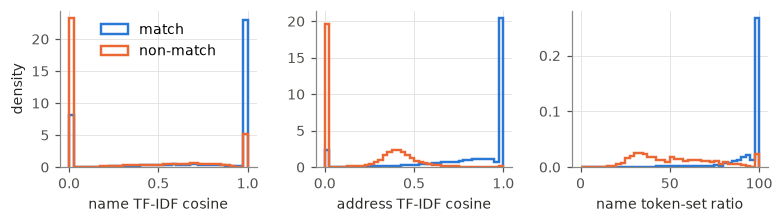

In [5]:
STR_FEATS = ["n_ratio", "n_tsort", "n_tset", "n_partial", "n_jw", "a_tset", "a_tsort", "a_partial", "num_jac", "num_first"]
LOG_FEATS = ["n_cand_s1", "n_s1_cand", "q_addr_len", "c_addr_len", "q_name_len", "c_name_len"]
FEATS = A_FEATS + STR_FEATS + ["num_missing"]


def prep(df: pl.DataFrame) -> pl.DataFrame:
    return df.with_columns(
        (pl.col("num_jac") < 0).cast(pl.Float32).alias("num_missing"),
        *[pl.col(c).cast(pl.Float32).log1p() for c in LOG_FEATS],
        *[pl.col(c).cast(pl.Float32) for c in ("is_s3", "c_addr_empty", "c_indic")],
    )


pairs = prep(pairs)
print(len(FEATS), "features")

fig, axes = plt.subplots(1, 3, figsize=(7.2, 2.1))
sample = pairs.sample(400_000, seed=SEED)
for ax, (f, lab) in zip(axes, (("name_cos", "name TF-IDF cosine"), ("addr_cos", "address TF-IDF cosine"),
                               ("n_tset", "name token-set ratio"))):
    for y, col, name in ((1, C["match"], "match"), (0, C["non"], "non-match")):
        x = sample.filter(pl.col("y") == y)[f].to_numpy()
        ax.hist(x, bins=40, density=True, histtype="step", color=col, lw=1.6, label=name)
    ax.set_xlabel(lab)
axes[0].set_ylabel("density")
axes[0].legend(loc="upper center")
save(fig, "fig_feature_dist")

### Feature selection
Tree models handle redundant inputs, but LDA/QDA need a well-conditioned covariance matrix and logistic
regression coefficients become unstable under collinearity. We drop one feature of every pair with
|Pearson r| > 0.95 (computed on the training folds) for the linear and discriminant models.

dropped: ['a_partial', 'a_tsort', 'c_addr_len', 'num_first', 'nword_cos_gap_s1']
38 features kept for LR/LDA/QDA


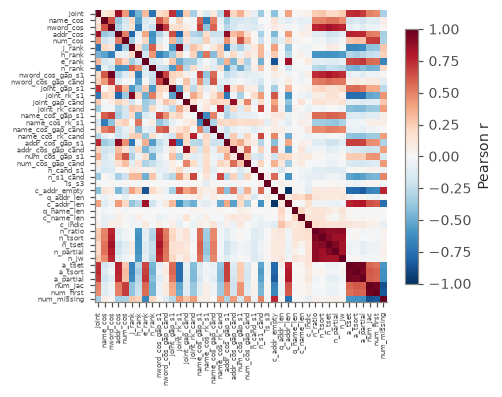

In [6]:
tr_sample = pairs.filter(pl.col("split").is_in(["f1", "f2", "f3"])).sample(300_000, seed=SEED)
corr = np.corrcoef(tr_sample.select(FEATS).to_numpy().astype(np.float64), rowvar=False)
corr = np.nan_to_num(corr)
drop = set()
for i in range(len(FEATS)):
    for j in range(i + 1, len(FEATS)):
        if FEATS[i] not in drop and FEATS[j] not in drop and abs(corr[i, j]) > 0.95:
            drop.add(FEATS[j])
LIN_FEATS = [f for f in FEATS if f not in drop]
print("dropped:", sorted(drop))
print(len(LIN_FEATS), "features kept for LR/LDA/QDA")
RESULTS["feature_selection"] = {"all": len(FEATS), "kept": len(LIN_FEATS), "dropped": sorted(drop)}

fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(FEATS)), FEATS, rotation=90, fontsize=4.5)
ax.set_yticks(range(len(FEATS)), FEATS, fontsize=4.5)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.75, label="Pearson r")
save(fig, "fig_corr")

## 4. Validation design
The split unit is the Source 1 entity: all candidate pairs of an entity fall in the same fold, so no
entity is seen in both training and evaluation. Folds f0-f4 are the predefined dev folds and
`lock` is the held-out test set.

* hyperparameter search: 5-fold grouped CV over f0-f4 on a sample of entities
* final fit: f1-f3; threshold and early stopping: f4; test: lockbox

In [7]:
def xy(df, feats):
    # float64: LDA on millions of rows loses precision in float32 covariance estimates
    return df.select([pl.col(f).cast(pl.Float64) for f in feats]).to_numpy(), df["y"].to_numpy()


train = pairs.filter(pl.col("split").is_in(["f1", "f2", "f3"]))
valid = pairs.filter(pl.col("split") == "f4")
test = pairs.filter(pl.col("split") == "lock")
print({k: (d.height, d["s1_id"].n_unique()) for k, d in (("train", train), ("valid", valid), ("test", test))})

dev_ids = ent.filter(pl.col("split") != "lock")["s1_id"].sample(15_000, seed=SEED)
cv = pairs.filter(pl.col("s1_id").is_in(dev_ids.implode()))
cv_groups = cv["split"].to_numpy()
gkf = GroupKFold(n_splits=5)
print("CV sample:", cv.height, "pairs")

{'train': (2781285, 52967), 'valid': (931499, 17727), 'test': (1139288, 21685)}
CV sample: 788079 pairs


## 5. Hyperparameter tuning
**Grid search** for logistic regression (inverse regularisation C, class weighting), LDA (shrinkage) and
QDA (covariance regularisation); **random search** for LightGBM. Scoring is average precision, which suits
the 3% positive rate better than accuracy.

In [8]:
t0 = time.time()
Xcv_lin, ycv = xy(cv, LIN_FEATS)
Xcv_all, _ = xy(cv, FEATS)
searches = {}
searches["LR"] = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10], "logisticregression__class_weight": [None, "balanced"]},
    scoring="average_precision", cv=gkf, n_jobs=8).fit(Xcv_lin, ycv, groups=cv_groups)
searches["LDA"] = GridSearchCV(
    make_pipeline(StandardScaler(), LinearDiscriminantAnalysis(solver="lsqr")),
    {"lineardiscriminantanalysis__shrinkage": [None, 0.001, 0.01, 0.1, "auto"]},
    scoring="average_precision", cv=gkf, n_jobs=8).fit(Xcv_lin, ycv, groups=cv_groups)
searches["QDA"] = GridSearchCV(
    make_pipeline(StandardScaler(), QuadraticDiscriminantAnalysis()),
    {"quadraticdiscriminantanalysis__reg_param": [0.0, 0.01, 0.05, 0.1, 0.3, 0.6]},
    scoring="average_precision", cv=gkf, n_jobs=8).fit(Xcv_lin, ycv, groups=cv_groups)
searches["LightGBM"] = RandomizedSearchCV(
    lgb.LGBMClassifier(n_estimators=300, subsample_freq=1, verbose=-1, n_jobs=16, random_state=SEED),
    {"num_leaves": stats.randint(8, 256), "learning_rate": stats.loguniform(0.02, 0.2),
     "min_child_samples": stats.randint(20, 500), "subsample": stats.uniform(0.6, 0.4),
     "colsample_bytree": stats.uniform(0.5, 0.5), "reg_lambda": stats.loguniform(1e-3, 10)},
    n_iter=10, scoring="average_precision", cv=gkf, n_jobs=1, random_state=SEED).fit(Xcv_all, ycv, groups=cv_groups)
tuning = {}
for k, s in searches.items():
    tuning[k] = {"best_params": {p.split("__")[-1]: (float(v) if isinstance(v, (float, np.floating)) else v)
                                 for p, v in s.best_params_.items()},
                 "cv_ap_mean": float(s.best_score_), "cv_ap_std": float(s.cv_results_["std_test_score"][s.best_index_])}
    print(k, tuning[k])
RESULTS["tuning"] = tuning
pd.DataFrame(searches["LR"].cv_results_)[["params", "mean_test_score", "std_test_score"]].to_csv(REP / "grid_lr.csv", index=False)
print(f"tuning took {time.time() - t0:.0f}s")

LR {'best_params': {'C': 1, 'class_weight': None}, 'cv_ap_mean': 0.997421415282326, 'cv_ap_std': 0.00012990046607301488}
LDA {'best_params': {'shrinkage': None}, 'cv_ap_mean': 0.9857186726712204, 'cv_ap_std': 0.0009326655154011976}
QDA {'best_params': {'reg_param': 0.1}, 'cv_ap_mean': 0.9916503743907313, 'cv_ap_std': 0.00037380485206760206}
LightGBM {'best_params': {'colsample_bytree': 0.6096728174634615, 'learning_rate': 0.05176565725942432, 'min_child_samples': 97, 'num_leaves': 85, 'reg_lambda': 0.002267754756842001, 'subsample': 0.7917159438720727}, 'cv_ap_mean': 0.9991184213765061, 'cv_ap_std': 8.329573068041372e-05}
tuning took 1144s


## 6. Logistic regression: coefficient estimation and inference
Maximum-likelihood fit with `statsmodels` on standardised inputs, using an interpretable subset of the
features. Each coefficient is the change in log-odds of a match per standard deviation of the feature;
exp(beta) is the odds ratio.

                     0                 1                  2          3
0               Model:             Logit            Method:        MLE
1  Dependent Variable:                 y  Pseudo R-squared:      0.948
2                Date:  2026-10-15 15:05               AIC:  6238.1160
3    No. Observations:            250000               BIC:  6404.9834
4            Df Model:                15    Log-Likelihood:    -3103.1
5        Df Residuals:            249984           LL-Null:    -59940.
6           Converged:            1.0000       LLR p-value:     0.0000
7      No. Iterations:           14.0000             Scale:     1.0000
       feature     beta     se        z      p  odds_ratio   ci_low  ci_high
         const -13.7836 0.3080 -44.7567 0.0000      0.0000   0.0000   0.0000
      name_cos   0.3724 0.0377   9.8738 0.0000      1.4513   1.3478   1.5626
     nword_cos   0.8260 0.0761  10.8562 0.0000      2.2843   1.9678   2.6516
      addr_cos   0.2202 0.0906   2.4300 0.0151      1

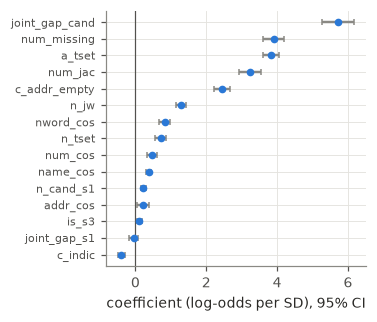

In [9]:
INF_FEATS = ["name_cos", "nword_cos", "addr_cos", "num_cos", "n_tset", "n_jw", "a_tset", "num_jac", "num_missing",
             "joint_gap_s1", "joint_gap_cand", "n_cand_s1", "is_s3", "c_addr_empty", "c_indic"]
inf = train.sample(250_000, seed=SEED)
Xi, yi = xy(inf, INF_FEATS)
mu, sd = Xi.mean(0), Xi.std(0)
logit = sm.Logit(yi, sm.add_constant((Xi - mu) / sd)).fit(disp=0, maxiter=200)
coef = pd.DataFrame({"feature": ["const"] + INF_FEATS, "beta": logit.params, "se": logit.bse, "z": logit.tvalues,
                     "p": logit.pvalues, "odds_ratio": np.exp(logit.params),
                     "ci_low": np.exp(logit.conf_int()[:, 0]), "ci_high": np.exp(logit.conf_int()[:, 1])})
coef.to_csv(REP / "logit_coefficients.csv", index=False)
print(logit.summary2().tables[0].to_string())
print(coef.round(4).to_string(index=False))
RESULTS["logit"] = {"pseudo_r2": float(logit.prsquared), "llf": float(logit.llf), "aic": float(logit.aic),
                    "n": int(len(yi)), "coef": coef.round(4).to_dict("records")}

c2 = coef[coef.feature != "const"].sort_values("beta")
fig, ax = plt.subplots(figsize=(3.5, 3.0))
ax.errorbar(c2.beta, range(len(c2)), xerr=1.96 * c2.se, fmt="o", ms=4, color=C["LR"], ecolor="#8a8984", capsize=2)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks(range(len(c2)), c2.feature, fontsize=7)
ax.set_xlabel("coefficient (log-odds per SD), 95% CI")
save(fig, "fig_logit_coef")

## 7. Final models and pair-level evaluation on the lockbox
Each model is refit on f1-f3 with the tuned settings. LightGBM uses early stopping on f4. The decision
threshold that maximises F1 on f4 is then applied unchanged to the lockbox.

In [10]:
Xtr_l, ytr = xy(train, LIN_FEATS)
Xva_l, yva = xy(valid, LIN_FEATS)
Xte_l, yte = xy(test, LIN_FEATS)
Xtr_a, _ = xy(train, FEATS)
Xva_a, _ = xy(valid, FEATS)
Xte_a, _ = xy(test, FEATS)

models, fit_time = {}, {}
for k in ("LR", "LDA", "QDA"):
    t0 = time.time()
    models[k] = searches[k].best_estimator_.fit(Xtr_l, ytr)
    fit_time[k] = time.time() - t0
bp = searches["LightGBM"].best_params_
t0 = time.time()
lgbm = lgb.LGBMClassifier(n_estimators=3000, subsample_freq=1, verbose=-1, n_jobs=16, random_state=SEED, **bp)
lgbm.fit(Xtr_a, ytr, eval_set=[(Xtr_a[::5], ytr[::5]), (Xva_a, yva)], eval_names=["train", "valid"],
         eval_metric="binary_logloss", callbacks=[lgb.early_stopping(100, verbose=False)])
models["LightGBM"] = lgbm
fit_time["LightGBM"] = time.time() - t0
print("LightGBM best iteration", lgbm.best_iteration_)


def proba(k, part):
    X = {"valid": (Xva_l, Xva_a), "test": (Xte_l, Xte_a), "train": (Xtr_l, Xtr_a)}[part]
    return models[k].predict_proba(X[1] if k == "LightGBM" else X[0])[:, 1]


def best_threshold(y, p):
    pr, rc, th = precision_recall_curve(y, p)
    f1 = 2 * pr * rc / np.maximum(pr + rc, 1e-12)
    return float(th[np.argmax(f1[:-1])])


P_VA, P_TE, pair_rows = {}, {}, []
for k in models:
    P_VA[k], P_TE[k] = proba(k, "valid"), proba(k, "test")
    th = best_threshold(yva, P_VA[k])
    yhat = P_TE[k] >= th
    tn, fp, fn, tp = confusion_matrix(yte, yhat).ravel()
    pair_rows.append({"model": k, "auc_roc": roc_auc_score(yte, P_TE[k]), "pr_auc": average_precision_score(yte, P_TE[k]),
                      "f1": f1_score(yte, yhat), "precision": precision_score(yte, yhat), "recall": recall_score(yte, yhat),
                      "log_loss": log_loss(yte, np.clip(P_TE[k], 1e-7, 1 - 1e-7)), "brier": brier_score_loss(yte, P_TE[k]),
                      "threshold": th, "tp": int(tp), "fp": int(fp), "fn": int(fn), "tn": int(tn),
                      "train_auc": roc_auc_score(ytr[::5], proba(k, "train")[::5]), "fit_seconds": fit_time[k]})
pair_res = pd.DataFrame(pair_rows)
pair_res.to_csv(REP / "pair_metrics.csv", index=False)
RESULTS["pair_metrics"] = pair_res.round(5).to_dict("records")
print(pair_res.round(4).to_string(index=False))

LightGBM best iteration 541


   model  auc_roc  pr_auc     f1  precision  recall  log_loss  brier  threshold    tp   fp   fn      tn  train_auc  fit_seconds
      LR   0.9998  0.9972 0.9786     0.9733  0.9840    0.0081 0.0022     0.3893 73187 2011 1189 1062901     0.9998      10.8530
     LDA   0.9983  0.9845 0.9460     0.9676  0.9253    0.0760 0.0066     0.5373 68817 2303 5559 1062609     0.9979       9.3448
     QDA   0.9987  0.9884 0.9690     0.9677  0.9704    0.0386 0.0042     0.9870 72173 2412 2203 1062500     0.9984      13.9205
LightGBM   1.0000  0.9994 0.9885     0.9893  0.9878    0.0041 0.0011     0.5185 73470  797  906 1064115     1.0000     127.9198


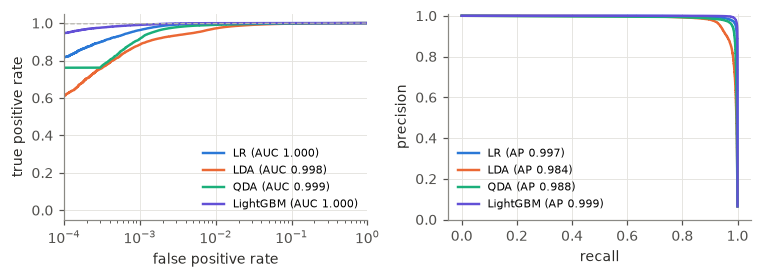

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
for k in models:
    fpr, tpr, _ = roc_curve(yte, P_TE[k])
    pr, rc, _ = precision_recall_curve(yte, P_TE[k])
    axes[0].plot(fpr, tpr, color=C[k], label=f"{k} (AUC {roc_auc_score(yte, P_TE[k]):.3f})")
    axes[1].plot(rc, pr, color=C[k], label=f"{k} (AP {average_precision_score(yte, P_TE[k]):.3f})")
axes[0].plot([0, 1], [0, 1], color="#b5b4ad", lw=0.8, ls="--")
axes[0].set(xlabel="false positive rate", ylabel="true positive rate", xscale="log", xlim=(1e-4, 1))
axes[1].set(xlabel="recall", ylabel="precision", ylim=(0, 1.01))
axes[0].legend(fontsize=7, loc="lower right")
axes[1].legend(fontsize=7, loc="lower left")
save(fig, "fig_roc_pr")

## 8. Entity-level evaluation (challenge metric)
The challenge scores each Source 1 entity by F0.5 between its predicted and true match sets and averages
over all entities (an entity with no true matches scores 1 only when nothing is predicted). True matches
that blocking missed count as false negatives. Three decision rules turn pair probabilities into a set:
* **0.5 threshold**: accept every candidate with p >= 0.5;
* **F1 threshold**: accept p >= the F1-optimal threshold from f4;
* **expected-F0.5 top-k**: sort candidates by p and pick the k (possibly 0) that maximises the expected F0.5.

In [12]:
test_ent = ent.filter(pl.col("split") == "lock")
n_true = dict(zip(test_ent["s1_id"].to_list(), test_ent["n_true"].to_list()))
country = dict(zip(test_ent["s1_id"].to_list(), test_ent["country"].to_list()))


def f05(tp, k, t):
    if t == 0:
        return 1.0 if k == 0 else 0.0
    if k == 0 or tp == 0:
        return 0.0
    p, r = tp / k, tp / t
    return 1.25 * p * r / (0.25 * p + r)


def entity_scores(prob, rule, th=0.5):
    d = pl.DataFrame({"s1_id": test["s1_id"], "y": yte, "p": prob}).sort(["s1_id", "p"], descending=[False, True])
    chosen = {}
    for (s1,), g in d.group_by("s1_id", maintain_order=True):
        p, y = g["p"].to_numpy(), g["y"].to_numpy()
        k = expected_f05_topk(p) if rule == "topk" else int((p >= th).sum())
        chosen[s1] = (int(y[:k].sum()), k)
    out = {}
    for s1, t in n_true.items():
        tp, k = chosen.get(s1, (0, 0))
        out[s1] = (f05(tp, k, t), k)
    return out


ent_rows = []
for k in models:
    th = next(r["threshold"] for r in pair_rows if r["model"] == k)
    for rule, t in (("0.5 threshold", 0.5), ("F1 threshold", th), ("expected-F0.5 top-k", None)):
        sc = entity_scores(P_TE[k], "topk" if t is None else "th", t if t is not None else 0.5)
        vals = np.array([v[0] for v in sc.values()])
        ks = np.array([v[1] for v in sc.values()])
        row = {"model": k, "rule": rule, "macro_f05": vals.mean(), "avg_predicted": ks.mean()}
        for cn in ("US", "India"):
            row[f"f05_{cn}"] = np.mean([v[0] for s, v in sc.items() if country[s] == cn])
        ent_rows.append(row)
ent_res = pd.DataFrame(ent_rows)
pos_by = dict(test.group_by("s1_id").agg(pl.col("y").sum()).iter_rows())
ceiling = np.mean([f05(pos_by.get(s, 0), pos_by.get(s, 0), t) for s, t in n_true.items()])
ent_res.to_csv(REP / "entity_metrics.csv", index=False)
RESULTS["entity_metrics"] = ent_res.round(5).to_dict("records")
RESULTS["entity_ceiling"] = ceiling
print(f"ceiling (perfect classifier on the blocked candidates): {ceiling:.4f}")
print(ent_res.round(4).to_string(index=False))

ceiling (perfect classifier on the blocked candidates): 0.9979
   model                rule  macro_f05  avg_predicted  f05_US  f05_India
      LR       0.5 threshold     0.9703         3.4368  0.9706     0.9698
      LR        F1 threshold     0.9683         3.4677  0.9693     0.9668
      LR expected-F0.5 top-k     0.9716         3.3518  0.9720     0.9710
     LDA       0.5 threshold     0.9473         3.2823  0.9563     0.9339
     LDA        F1 threshold     0.9475         3.2797  0.9563     0.9342
     LDA expected-F0.5 top-k     0.9477         3.2661  0.9564     0.9348
     QDA       0.5 threshold     0.9476         3.5448  0.9579     0.9323
     QDA        F1 threshold     0.9581         3.4395  0.9650     0.9476
     QDA expected-F0.5 top-k     0.9512         3.5156  0.9604     0.9374
LightGBM       0.5 threshold     0.9840         3.4278  0.9849     0.9828
LightGBM        F1 threshold     0.9843         3.4248  0.9853     0.9829
LightGBM expected-F0.5 top-k     0.9855         3

## 9. Overfitting and underfitting
Left: training and validation log-loss of a deliberately flexible LightGBM (255 leaves, small leaf size)
as trees are added; the gap opens once the model starts fitting noise and early stopping picks the turning point.
Right: capacity of a single decision tree (maximum depth) against average precision - shallow trees
underfit (both curves low), deep trees memorise the training folds and the validation score falls.

{'best_round': 87, 'valid_min': 0.005391740098372193, 'valid_last': 0.010190234240955694, 'train_last': 4.056862454271308e-08, 'capacity': [{'max_depth': 1, 'leaves': 2, 'train_ap': 0.808, 'valid_ap': 0.80675}, {'max_depth': 2, 'leaves': 4, 'train_ap': 0.92422, 'valid_ap': 0.92474}, {'max_depth': 3, 'leaves': 8, 'train_ap': 0.9545, 'valid_ap': 0.95494}, {'max_depth': 4, 'leaves': 16, 'train_ap': 0.96358, 'valid_ap': 0.96413}, {'max_depth': 6, 'leaves': 57, 'train_ap': 0.98598, 'valid_ap': 0.98536}, {'max_depth': 8, 'leaves': 153, 'train_ap': 0.99226, 'valid_ap': 0.98758}, {'max_depth': 12, 'leaves': 668, 'train_ap': 0.99732, 'valid_ap': 0.98215}, {'max_depth': 16, 'leaves': 1455, 'train_ap': 0.99917, 'valid_ap': 0.96643}, {'max_depth': 24, 'leaves': 2194, 'train_ap': 1.0, 'valid_ap': 0.95187}, {'max_depth': 32, 'leaves': 2216, 'train_ap': 1.0, 'valid_ap': 0.95087}, {'max_depth': 48, 'leaves': 2216, 'train_ap': 1.0, 'valid_ap': 0.95087}]}


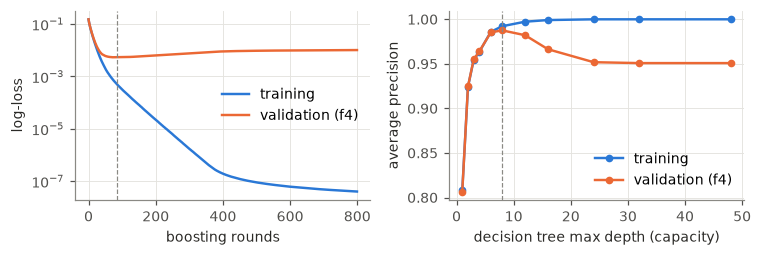

In [13]:
sub_ids = ent.filter(pl.col("split").is_in(["f1", "f2", "f3"]))["s1_id"].sample(20_000, seed=SEED)
sub = train.filter(pl.col("s1_id").is_in(sub_ids.implode()))
Xs, ys = xy(sub, FEATS)
ev = {}
flex = lgb.train({"objective": "binary", "learning_rate": 0.1, "num_leaves": 255, "min_data_in_leaf": 5,
                  "verbose": -1, "num_threads": 16, "seed": SEED},
                 lgb.Dataset(Xs, ys), 800, valid_sets=[lgb.Dataset(Xs, ys), lgb.Dataset(Xva_a, yva)],
                 valid_names=["train", "valid"], callbacks=[lgb.record_evaluation(ev)])
tr_curve, va_curve = np.array(ev["train"]["binary_logloss"]), np.array(ev["valid"]["binary_logloss"])
cap_rows = []
for depth in (1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48):
    m = DecisionTreeClassifier(max_depth=depth, random_state=SEED).fit(Xs, ys)
    cap_rows.append({"max_depth": depth, "leaves": int(m.get_n_leaves()),
                     "train_ap": average_precision_score(ys, m.predict_proba(Xs)[:, 1]),
                     "valid_ap": average_precision_score(yva, m.predict_proba(Xva_a)[:, 1])})
cap = pd.DataFrame(cap_rows)
cap.to_csv(REP / "capacity_curve.csv", index=False)
RESULTS["overfit"] = {"best_round": int(va_curve.argmin() + 1), "valid_min": float(va_curve.min()),
                      "valid_last": float(va_curve[-1]), "train_last": float(tr_curve[-1]), "capacity": cap.round(5).to_dict("records")}
print(RESULTS["overfit"])

fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.4))
axes[0].plot(tr_curve, color=C["LR"], label="training")
axes[0].plot(va_curve, color=C["LDA"], label="validation (f4)")
axes[0].axvline(va_curve.argmin(), color="#8a8984", lw=0.8, ls="--")
axes[0].set(xlabel="boosting rounds", ylabel="log-loss", yscale="log")
axes[0].legend()
axes[1].plot(cap.max_depth, cap.train_ap, "o-", color=C["LR"], ms=4, label="training")
axes[1].plot(cap.max_depth, cap.valid_ap, "o-", color=C["LDA"], ms=4, label="validation (f4)")
axes[1].axvline(cap.max_depth[cap.valid_ap.idxmax()], color="#8a8984", lw=0.8, ls="--")
axes[1].set(xlabel="decision tree max depth (capacity)", ylabel="average precision")
axes[1].legend()
save(fig, "fig_overfit")

## 10. Count models: how many matches does an entity have?
The number of true matches per entity is a count (0, 1, 2, ...). We model it from entity-level
summaries of the candidate list with a **Poisson GLM**, a **negative binomial** regression (which allows
variance > mean) and a **multinomial logit** over the classes {0, 1, 2, 3+}. Errors are reported as MAE
and RMSE on the lockbox.

In [14]:
def entity_features(df: pl.DataFrame) -> pl.DataFrame:
    return df.group_by("s1_id").agg(
        pl.len().alias("n_cand"),
        (pl.col("n_tset") >= 90).sum().alias("n_name_strong"),
        (pl.col("joint") >= 0.5).sum().alias("n_joint_hi"),
        ((pl.col("n_tset") >= 90) & (pl.col("a_tset") >= 70)).sum().alias("n_both_strong"),
        pl.col("joint").max().alias("max_joint"),
        pl.col("n_tset").max().alias("max_n_tset"),
        pl.col("q_addr_len").first().alias("q_addr_len"),
        pl.col("q_name_len").first().alias("q_name_len"),
    )


CNT_FEATS = ["n_name_strong", "n_joint_hi", "n_both_strong", "max_joint", "max_n_tset", "q_addr_len", "q_name_len", "india"]
ef = (ent.select("s1_id", "country", "split", "n_true").join(entity_features(pairs), on="s1_id", how="left")
      .fill_null(0).with_columns((pl.col("country") == "India").cast(pl.Float64).alias("india"),
                                 pl.col("n_name_strong", "n_joint_hi", "n_both_strong").log1p(),
                                 (pl.col("max_n_tset") / 100)))
e_tr, e_te = ef.filter(pl.col("split") != "lock"), ef.filter(pl.col("split") == "lock")
Xc_tr = sm.add_constant(e_tr.select(CNT_FEATS).to_numpy().astype(float))
Xc_te = sm.add_constant(e_te.select(CNT_FEATS).to_numpy().astype(float))
yc_tr, yc_te = e_tr["n_true"].to_numpy(), e_te["n_true"].to_numpy()

pois = sm.GLM(yc_tr, Xc_tr, family=sm.families.Poisson()).fit()
nb = sm.NegativeBinomial(yc_tr, Xc_tr).fit(disp=0, maxiter=300)
disp = float(pois.pearson_chi2 / pois.df_resid)
cls_tr, cls_te = np.minimum(yc_tr, 3), np.minimum(yc_te, 3)
mnl = sm.MNLogit(cls_tr, Xc_tr).fit(disp=0, maxiter=300)
mu_p, mu_nb = pois.predict(Xc_te), nb.predict(Xc_te)
pred_cls = mnl.predict(Xc_te).argmax(1)
count_res = pd.DataFrame([
    {"model": "Poisson GLM", "aic": pois.aic, "mae": mean_absolute_error(yc_te, mu_p),
     "rmse": mean_squared_error(yc_te, mu_p) ** 0.5, "mae_rounded": mean_absolute_error(yc_te, np.round(mu_p)),
     "exact_count_acc": float((np.round(mu_p) == yc_te).mean()),
     "class_acc_0123": float((np.minimum(np.round(mu_p), 3) == cls_te).mean())},
    {"model": "Negative binomial", "aic": nb.aic, "mae": mean_absolute_error(yc_te, mu_nb),
     "rmse": mean_squared_error(yc_te, mu_nb) ** 0.5, "mae_rounded": mean_absolute_error(yc_te, np.round(mu_nb)),
     "exact_count_acc": float((np.round(mu_nb) == yc_te).mean()),
     "class_acc_0123": float((np.minimum(np.round(mu_nb), 3) == cls_te).mean())},
    {"model": "Multinomial logit (0/1/2/3+)", "aic": mnl.aic, "mae": mean_absolute_error(cls_te, pred_cls),
     "rmse": mean_squared_error(cls_te, pred_cls) ** 0.5, "mae_rounded": mean_absolute_error(cls_te, pred_cls),
     "exact_count_acc": float("nan"), "class_acc_0123": float((pred_cls == cls_te).mean()), "macro_f1": f1_score(cls_te, pred_cls, average="macro")},
])
count_res.to_csv(REP / "count_models.csv", index=False)
pd.DataFrame({"feature": ["const"] + CNT_FEATS, "poisson_beta": pois.params, "poisson_p": pois.pvalues,
              "nb_beta": nb.params[:-1], "nb_p": nb.pvalues[:-1]}).to_csv(REP / "count_coefficients.csv", index=False)
RESULTS["count_models"] = {"pearson_dispersion": disp, "nb_alpha": float(nb.params[-1]),
                           "table": count_res.round(4).to_dict("records")}
print(f"Poisson Pearson dispersion {disp:.3f}, NB alpha {nb.params[-1]:.4f}")
print(count_res.round(4).to_string(index=False))

Poisson Pearson dispersion 0.312, NB alpha 0.0000
                       model         aic    mae   rmse  mae_rounded  exact_count_acc  class_acc_0123  macro_f1
                 Poisson GLM 288006.4305 0.7132 0.9489       0.7067           0.4206          0.7629       NaN
           Negative binomial 288008.4413 0.7132 0.9489       0.7067           0.4206          0.7630       NaN
Multinomial logit (0/1/2/3+)  77702.5666 0.2112 0.5057       0.2112              NaN          0.8080    0.6022


**Count-guided selection.** The predicted count can also drive the decision: accept the top round(mu)
candidates ranked by the pair model. We compare it with the expected-F0.5 rule.

In [15]:
mu_map = dict(zip(e_te["s1_id"].to_list(), np.round(mu_nb).astype(int).tolist()))
best_pair = pair_res.sort_values("pr_auc").iloc[-1]["model"]
d = pl.DataFrame({"s1_id": test["s1_id"], "y": yte, "p": P_TE[best_pair]}).sort(["s1_id", "p"], descending=[False, True])
hits = {s1: g["y"].to_numpy() for (s1,), g in d.group_by("s1_id", maintain_order=True)}
cg = []
for s1, t in n_true.items():
    y = hits.get(s1, np.array([]))
    k = min(mu_map.get(s1, 0), len(y))
    cg.append(f05(int(y[:k].sum()), k, t))
RESULTS["count_guided_f05"] = {"model": best_pair, "macro_f05": float(np.mean(cg))}
print(RESULTS["count_guided_f05"])

{'model': 'LightGBM', 'macro_f05': 0.859891161219675}


## 11. Full challenge system
The same features feed the system we submitted to the Amazon ML Challenge 2026, trained on all 1.76M dev
entities: union blocking, a LightGBM pruning stage, a second LightGBM with sibling features and the
expected-F0.5 rule. Its development history (dev fold f0, full data) and public leaderboard scores:

In [16]:
hist = pd.read_csv(ROOT / "experiments" / "results.csv", sep="\t")
hist["portal"] = hist["notes"].str.extract(r"PORTAL ([0-9.]+)").astype(float)
hist = hist[["run_id", "description", "f05", "recall_ceiling", "avg_candidates", "portal"]]
RESULTS["challenge_runs"] = hist.to_dict("records")
print(hist.to_string(index=False))

run_id                                                                                                      description    f05  recall_ceiling  avg_candidates  portal
  r001                                                   joint tfidf top15 + lgb prune + lgb pair model + exp-F0.5 topk 0.9364          0.8881            4.27   0.902
  r002               v2: union blocking (joint@30 + empty-addr name@10 + num@10), translit, sibling feats, prune cap 10 0.9546          0.9346            5.59   0.927
  r003                                 r002 + stage B trained on all f1-f3 (es all f4); stage A unchanged (400k sample) 0.9535          0.9346            5.59     NaN
  r004 name-word view (max_df .03) + name-heavy@20 search, zero-strip, cross-fitted stage A (2x250k), stage B all f1-f3 0.9742          0.9732            5.14   0.959


## 12. Save artefacts for the paper and the dashboard

In [17]:
joblib.dump({"model": models["LR"], "feats": LIN_FEATS}, APP / "logreg.joblib")
models["LightGBM"].booster_.save_model(str(APP / "lightgbm.txt"))
json.dump({"lin_feats": LIN_FEATS, "feats": FEATS,
           "thresholds": {r["model"]: r["threshold"] for r in pair_rows}}, open(APP / "config.json", "w"), indent=1)

demo_ids = test_ent.sample(1500, seed=SEED)["s1_id"]
demo = test.filter(pl.col("s1_id").is_in(demo_ids.implode()))
demo = demo.with_columns(*[pl.Series(f"p_{k}", P_TE[k][test["s1_id"].is_in(demo_ids.implode()).to_numpy()]) for k in models])
keep_ids = pl.concat([demo["s1_id"], demo["cand_id"]]).unique()
demo.select("s1_id", "cand_id", "y", "country", *FEATS, *[f"p_{k}" for k in models]).write_parquet(ROOT / "app" / "demo_pairs.parquet")
recs.filter(pl.col("entity_id").is_in(keep_ids.implode())).select(
    "entity_id", "src", "country", "business_name", "business_address").write_parquet(ROOT / "app" / "demo_records.parquet")
test_ent.filter(pl.col("s1_id").is_in(demo_ids.implode())).select("s1_id", "country", "n_true").write_parquet(
    ROOT / "app" / "demo_entities.parquet")

json.dump(RESULTS, open(REP / "results.json", "w"), indent=1, default=float)
print("saved")

saved
